# PyTorch Computer Vision

- See reference notebook - https://github.com/mrdbourke/pytorch-deep-learning/blob/main/03_pytorch_computer_vision.ipynb
- See reference online book - https://www.learnpytorch.io/03_pytorch_computer_vision/


## 0. Computer vision libaries in PyTorch

- `torchvision` - base domain library for PyTorch computer vision
- `torchvision.datasets` - get datasets and data loading functions for computer vision here
- `torchvision.models` - get pretrained computer vision models that you can leverage for your own problems
- `torchvision.transforms` - functions for manipulating your vision data (images) to be suitable for use with an ML model
- `torch.utils.data.Dataset` - Base dataset class for PyTorch.
- `torch.utils.data.DataLoader` - Creates a Python iterable over a dataset

In [1]:
#import Pytorch
import torch
from torch import nn

#import torchvision
import torchvision
from torchvision import datasets,transforms
from torchvision.transforms import ToTensor

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Check versions
print(torch.__version__)
print(torchvision.__version__)

2.14.1+cu130
0.29.1+cu130


## 1. Getting a dataset

The dataset we'll be using is **FashionMNIST** from torchvision.datasets -https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html#torchvision.datasets.FashionMNIST

In [2]:
import torchvision

from torchvision import datasets, transforms

# Training dataset

train_data = datasets.FashionMNIST(

    root="data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
    target_transform=None

)

# Testing dataset

test_data = datasets.FashionMNIST(

    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
    target_transform=None

)



100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.81MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.82MB/s]


In [3]:
type(test_data)

#see the first training smaple

image,label=train_data[0]

image,label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [4]:
class_names=train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [5]:
class_to_idx=train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [6]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [7]:
#Check the shape of our image
print(f"Image Shape:{image.shape}->[color channels,height,width]")
print(f"Image label:{class_names[label]}")

Image Shape:torch.Size([1, 28, 28])->[color channels,height,width]
Image label:Ankle boot


## 1.2Visualing our data

Image shape:torch.Size([1, 28, 28])


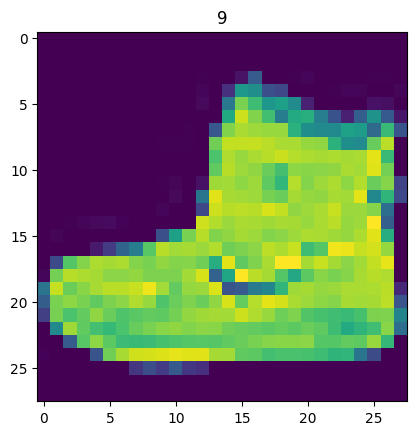

In [8]:
#visualize visualize !!

import matplotlib.pyplot as plt
image,label=train_data[0]
print(f"Image shape:{image.shape}")
plt.imshow(image.squeeze())
plt.title(label);
#image




(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

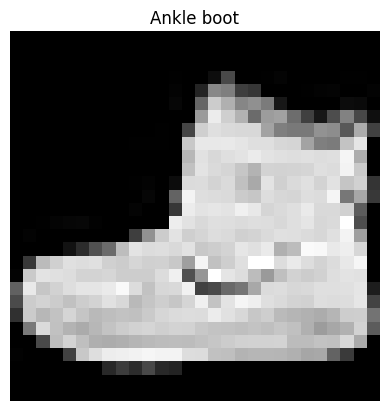

In [9]:
plt.imshow(image.squeeze(),cmap="gray")
#label is int
plt.title(class_names[label]);
plt.axis(False)

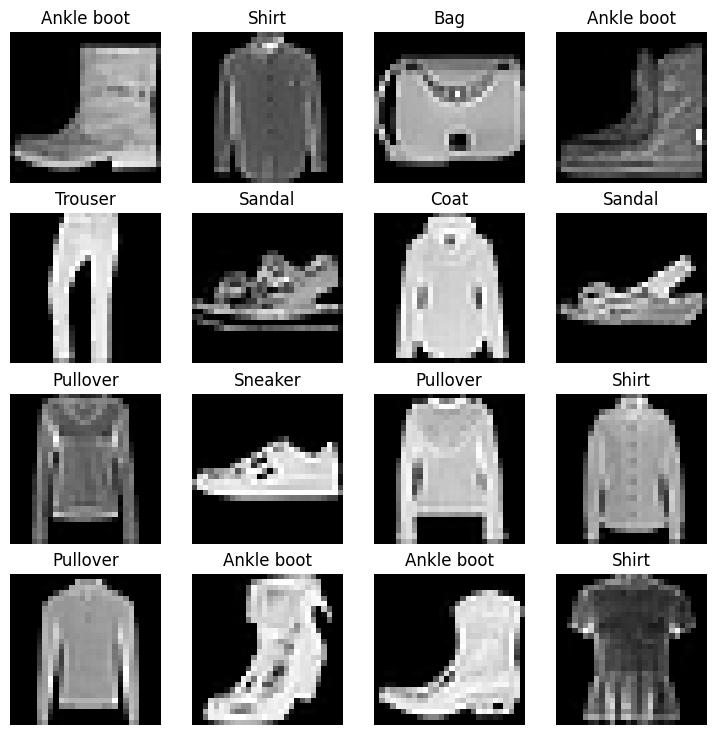

In [10]:
from matplotlib.figure import figaspect
#plot more images
torch.manual_seed(42)
fig=plt.figure(figsize=(9,9))
rows,cols=4,4
for i in range(1,rows*cols+1):
  random_idx=torch.randint(0,len(train_data),size=[1]).item()
  img,label=train_data[random_idx]
  fig.add_subplot(rows,cols,i)
  plt.imshow(img.squeeze(),cmap="grey")
  plt.title(class_names[label])
  plt.axis(False)

Do you think these items of clothing (images) could be modelled with pure linear lines? or do you think we will need non linearity ??

## 2. Prepare DataLoader

Right now, our data is in the form of pytorch datasets.

Datalaoder turns our datasets into a Python Iterable.

More specifically, we want to turn our data into batches(or mini batches).

Why would we do this?

1. It is more computationally efficient, as in your computing hardware may not be able to look (store in memory) at 60000 images in one hit. so we break it down to 32 images at a time (batch size of 32).

2. It gives our neural network more chances to update its gradienta per epoch.

In [11]:
from torch.utils.data import DataLoader

#setup the batch size hyperparameter
BATCH_SIZE=32

#Turn datasets into iterables(batches)

train_dataloader=DataLoader(dataset=train_data,
                            batch_size=BATCH_SIZE,
                            shuffle=True)

test_dataloader=DataLoader(dataset=test_data,
                            batch_size=BATCH_SIZE,
                            shuffle=False)

train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7b90120d5a90>,
 <torch.utils.data.dataloader.DataLoader at 0x7b90112da710>)

In [12]:

# Let's check out what we've created
print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7b90120d5a90>, <torch.utils.data.dataloader.DataLoader object at 0x7b90112da710>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [13]:
# check out whats inside the training dataloader
train_feature_batch, train_labels_batch = next(iter(train_dataloader))
train_feature_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
labels: 6, label size: torch.Size([])


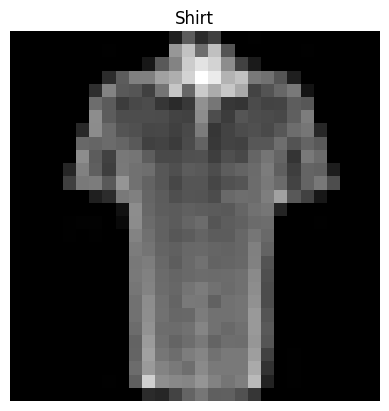

In [14]:
# show a sample

torch.manual_seed(42)
random_idx = torch.randint(0,len(train_feature_batch), size=[1]).item()
#注意這邊跟上面差別
img,label = train_feature_batch[random_idx],train_labels_batch[random_idx]
fig.add_subplot(rows,cols,i)
plt.imshow(img.squeeze(),cmap="gray")
plt.title(class_names[label])
plt.axis(False)

print(f"Image size: {img.shape}")
print(f"labels: {label}, label size: {label.shape}")

## 3.Model 0: Build a baseline model

When starting to build a series of machine learning modelling experiments, its best practice to start with a baseline model.

A baseline model is a simple model you will try and improve upon with subsequent models.

In other words: start simply and add complexity when necessary

In [15]:
# Creating the flatten layer
flatten_model = nn.Flatten()

# Get a single sample. it's whole shape:torch.Size([32, 1, 28, 28])
x = train_feature_batch[0]

#flatten the sample
output = flatten_model(x)

# Print out what happening
print(f"Shape before flatenning:{x.shape} -> [color_channel,height,width]")
print(f"Shape after flatenning: {output.shape} -> [color_channel,height*width]")


Shape before flatenning:torch.Size([1, 28, 28]) -> [color_channel,height,width]
Shape after flatenning: torch.Size([1, 784]) -> [color_channel,height*width]


In [16]:
output

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0039, 0.0039, 0.0000, 0.0000, 0.0078, 0.0078,
         0.0000, 0.0000, 0.0039, 0.0078, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.2863, 0.0000, 0.0

In [17]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_units:int,
               output_shape:int):
      super().__init__()
      self.layer_stack=nn.Sequential(
          nn.Flatten(),
          nn.Linear(in_features=input_shape,
                    out_features=hidden_units),
          nn.Linear(in_features=hidden_units,
                    out_features=output_shape)
      )

  def forward(self,x):
    return self.layer_stack(x)

In [18]:
torch.manual_seed(42)


#setup model with input paramters

model_0 = FashionMNISTModelV0(
    input_shape= 784, # 28 x 28
    hidden_units= 10,
    output_shape=len(class_names)
)

model_0.to("cpu")

model_0

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [19]:
dummy_x = torch.rand([1,1,28,28])
model_0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [20]:
# state_dict()：回傳模型的狀態字典，包含可學習參數（weights、biases）及已註冊的 buffers，常用於儲存與載入模型。
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

### 3.1 setup loss, optimizer and evaluation metrics

* Loss function - Since we are working with multi-class data, our loss function will `nn.CrossEntropyLoss()`

* Optimizer - our optimizer `torch.optim.SGD()`

* Evaluation metric - since we are walking on a classification problem, lets use accuracy as our evaluation metric

In [21]:
import requests
from pathlib import Path

# Download the helper functions from Learn pytorch repo.

if Path("helper_functions.py").is_file():
    print("helper_functions.py is exists")

else:
    print(" Download the helper_function.py")
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
    with open("helper_functions.py","wb") as f:
        f.write(request.content)

 Download the helper_function.py


In [22]:
# 取得模型所有可學習參數（weights、biases），通常用於 Optimizer 更新權重
model_0.parameters

<bound method Module.parameters of FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)>

In [23]:
# Import accuracy metric
#剛剛仔入的 lib
from helper_functions import accuracy_fn

# setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
                            params=model_0.parameters(),
                            lr =0.1)

### 3.2 Creating a function to time our experiments

Machine learning is very experimental.

Two of the main things you will often want to track are:

1. Model's performance(loss and accuracy values)
2. How fast it runs

In [24]:
from  timeit import default_timer as timer

def print_train_time(start:float,
                     end:float,
                     device: torch.device = None):
    """Prints difference between start and end time"""
    total_time = end - start

    print(f"Train time on {device}: {total_time:.3f} seconds")

    return total_time

In [25]:
#and the pattern should look like this
start_time = timer()
num=0

max=1000000

while(num<max):
  num+=1

end_time = timer()
print_train_time(start=start_time,end=end_time,device="cpu")

Train time on cpu: 0.111 seconds


0.11134835699999712

### 3.3 Creating the training loop and training a model on batch of data

1. Loop through epochs
2. Loop through training batches, perform training steps, calculate the train loss per batch.
3. Loop through testing batches, perform testing steps, calculate the test loss per batch
4. Print out what's happening.
Time it all

In [26]:
#import tqdm for progress bar
from tqdm.auto import tqdm


#set the seed and start the timer
torch.manual_seed(42)
train_time_start_on_cpu=timer()

epochs=3

for epoch in tqdm(range(epochs)):
    print(f"Epoch:{epoch+1}\n------")
    ### Training
    train_loss=0
    # Add a loop to loop through the training batches
    for batch, (X,y) in enumerate(train_dataloader):
          model_0.train()

          y_pred = model_0(X)

          # calcualte the loss
          loss = loss_fn(y_pred,y)
          train_loss += loss # accumulate the train loss

          optimizer.zero_grad()

          loss.backward()

          optimizer.step()

          # print what happening
          if batch % 400 == 0:
              print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples.")

    # Divide total train loss by length of train dataloader
    train_loss /= len(train_dataloader)

    ###testing
    test_loss,test_acc=0,0
    model_0.eval()

    with torch.inference_mode():
        for X,y in test_dataloader:
          test_pred=model_0(X)
          test_loss+=loss_fn(test_pred,y)
          test_acc+=accuracy_fn(y_true=y,y_pred=test_pred.argmax(dim=1))

        #calculate the test loss
        test_loss/=len(test_dataloader)
        #calculate the test acc
        test_acc/=len(test_dataloader)

    print(f"Train loss:{train_loss:.4f} | test_loss:{test_loss:.4f} | test_acc:{test_acc:.4f}")

#Calculate the training time
train_time_end_on_cpu=timer()
total_train_time_model_0=print_train_time(start=train_time_start_on_cpu,
                 end=train_time_end_on_cpu,
                 device="cpu")

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:1
------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.5904 | test_loss:0.5095 | test_acc:82.0387
Epoch:2
------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.4763 | test_loss:0.4799 | test_acc:83.1969
Epoch:3
------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.4550 | test_loss:0.4766 | test_acc:83.4265
Train time on cpu: 26.060 seconds


In [27]:
# parameters() 回傳模型參數的迭代器
# next() 取得第一個參數，.device 查看其所在裝置（CPU/GPU）
str(next(model_0.parameters()).device)

'cpu'

## 4.Make prediction and get Model 0 results

In [28]:
#主要用於測試data
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn):

    loss, acc = 0, 0
    model.eval()

    with torch.inference_mode():
        for X, y in data_loader:
            y_pred = model(X)


            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

        loss /= len(data_loader)
        acc /= len(data_loader)

    return {
        "model_name": model.__class__.__name__,
        "model_loss": loss.item(),
        "model_acc": acc
    }

#Calculate model 0 result on test dataset
model_0_results = eval_model(
                            model=model_0,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn
)

model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': 83.42651757188499}

## 5.setup the device agnostic code

In [29]:
device="cuda" if torch.cuda.is_available() else "cpu"

device

'cuda'

## 6.Model 1: Building the model with non linearity

In [30]:
# Create the model with non linear layers (because of ReLu)
class FashionMNISTModelV1(nn.Module):
    def __init__(self,
                 input_shape:int,
                 hidden_unit:int,
                 output_shape:int):
        super().__init__()

        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,
                      out_features=hidden_unit),
            nn.ReLU(),
            nn.Linear(in_features=hidden_unit,
                      out_features=output_shape),
            nn.ReLU()

        )

    def forward(self,x:torch.Tensor):
        return self.layer_stack(x)


In [31]:
str(next(model_0.parameters()).device)

'cpu'

In [32]:
#create the instance of model 1
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(
                            input_shape= 784,
                            hidden_unit=10,
                            output_shape=len(class_names))

model_1.to(device);

In [33]:
str(next(model_1.parameters()).device)


#下次進到 setup  model_1's loss,optimzer

'cuda:0'

In [34]:
#create the instance of model 1
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(
                            input_shape= 784,
                            hidden_unit=10,
                            output_shape=len(class_names)).to(device)

In [35]:
next(model_1.parameters()).device

device(type='cuda', index=0)

### 6.1setup loss, optimizer and evalution metrics

In [36]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), # tries to update our models parameter to reduce the loss
                            lr=0.1)

### 6.2Funnctionizing training and evalution/testing loops


In [37]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device):
  train_loss,train_acc=0,0
  model.to(device)

  #default
  model.train()
  for batch,(X,y) in enumerate(data_loader):
      X,y=X.to(device),y.to(device)

      # 1. Optimizer zero grad
      optimizer.zero_grad()
      # 2. Forward pass
      y_pred=model(X)
      # 3. Calculate loss
      loss=loss_fn(y_pred,y)
      train_loss+=loss
      train_acc+=accuracy_fn(y_true=y,
                            y_pred=y_pred.argmax(dim=1))# Go from logits -> pred labels

      loss.backward()

      # 5. Optimizer step
      optimizer.step()

  # Calculate loss and accuracy per epoch and print out what's happening
  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")






In [38]:
def test_step(data_loader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval() # put model in eval mode
    # Turn on inference context manager
    with torch.no_grad():
        for X, y in data_loader:
            # Send data to GPU
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred = model(X)

            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y)
            test_acc += accuracy_fn(y_true=y,
                y_pred=test_pred.argmax(dim=1) # Go from logits -> pred labels
            )

        # Adjust metrics and print out
        test_loss /= len(data_loader)
        test_acc /= len(data_loader)
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")

In [39]:
from tqdm.auto import tqdm
from timeit import default_timer as Timer

torch.manual_seed(42)

train_time_start_on_gpu=timer()

epochs=3

for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n---------")
    train_step(model=model_1,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device=device)

    test_step(model=model_1,
              data_loader=test_dataloader,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn,
              device=device)

train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start=train_time_start_on_gpu,
                                            end=train_time_end_on_gpu,
                                            device=device)


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
---------
Train loss: 1.09199 | Train accuracy: 61.34%
Test loss: 0.95636 | Test accuracy: 65.00%

Epoch: 1
---------
Train loss: 0.78101 | Train accuracy: 71.93%
Test loss: 0.72227 | Test accuracy: 73.91%

Epoch: 2
---------
Train loss: 0.67027 | Train accuracy: 75.94%
Test loss: 0.68500 | Test accuracy: 75.02%

Train time on cuda: 30.622 seconds


In [40]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': 83.42651757188499}

In [41]:
total_train_time_model_0

26.059729957000002

In [42]:
total_train_time_model_1

30.621866194000063

In [43]:
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device=device):

    loss, acc = 0, 0
    model.eval()

    with torch.no_grad():
        for X, y in data_loader:
            X,y = X.to(device),y.to(device)
            #forward
            y_pred = model(X)

            #calculate loss
            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

        loss /= len(data_loader)
        acc /= len(data_loader)

    return {
        "model_name": model.__class__.__name__,
        "model_loss": loss.item(),
        "model_acc": acc
    }

In [44]:
model_1_results = eval_model(
                            model=model_1,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn
)

model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850008964538574,
 'model_acc': 75.01996805111821}

In [45]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': 83.42651757188499}

## 7.Model 2: Building a Convolutional Neural Network(CNN)

CNN are also known as ConvNets

CNN are known for the capabilities to find pattern in visual data

In [46]:
class FashionMNISTModelV2(nn.Module):
    """
    Model architecture copying TinyVGG from:
    https://poloclub.github.io/cnn-explainer/
    """
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3, # how big is the square that's going over the image?
                      stride=1, # default
                      padding=1),# options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # default stride value is same as kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        with torch.no_grad():
            dummy = torch.randn(1, input_shape, 28, 28)
            x = self.conv_block_1(dummy)
            x = self.conv_block_2(x)
            n_features = x.shape[1] * x.shape[2] * x.shape[3]
            # n_features = x.numel
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Where did this in_features shape come from?
            # It's because each layer of our network compresses and changes the shape of our input data.
            nn.Linear(in_features=n_features,
                      out_features=output_shape)
        )
    def forward(self,x):
        x = self.conv_block_1(x)
        #print(f"Output shape of the conv_block_1:{x.shape}")
        x = self.conv_block_2(x)
        #print(f"Output shape of the conv_block_2: {x.shape}")
        x =  self.classifier(x)
        #print(f"Output shape of the classifier: {x.shape}")
        return x

In [47]:
torch.manual_seed(42)

model_2 = FashionMNISTModelV2(input_shape=1,
                              hidden_units=10,
                              output_shape=len(class_names)).to(device)

In [48]:
image.shape

torch.Size([1, 28, 28])

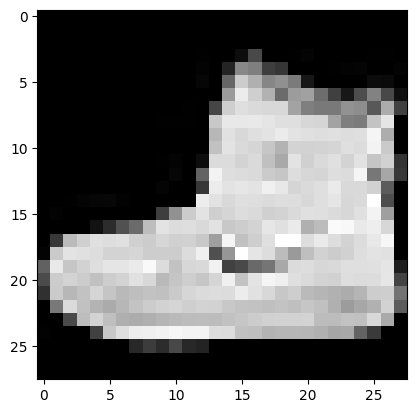

In [49]:
plt.imshow(image.squeeze(),cmap="gray")

In [50]:
rand_image_tensor = torch.randn(size=(1,1,28,28))
rand_image_tensor.shape

torch.Size([1, 1, 28, 28])

In [51]:
model_2(rand_image_tensor.to(device))

tensor([[ 0.0599, -0.0816,  0.1003,  0.0441,  0.0177, -0.0190,  0.0505,  0.0297,
         -0.0252,  0.0498]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [52]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.2548,  0.2767, -0.0781],
                        [ 0.3062, -0.0730,  0.0673],
                        [-0.1623,  0.1958,  0.2938]]],
              
              
                      [[[-0.2445,  0.2897,  0.0624],
                        [ 0.2463,  0.0451,  0.1607],
                        [-0.0471,  0.2570,  0.0493]]],
              
              
                      [[[-0.1556,  0.0850, -0.1536],
                        [-0.0391, -0.1354,  0.2211],
                        [-0.2631, -0.1537, -0.0941]]],
              
              
                      [[[-0.2004,  0.0315, -0.3292],
                        [ 0.3010, -0.2832,  0.2573],
                        [ 0.0555, -0.1082,  0.2060]]],
              
              
                      [[[ 0.0520,  0.2693,  0.0364],
                        [-0.1051,  0.0896, -0.0904],
                        [ 0.1403,  0.2976,  0.1927]]],
              
              
      

### 7.1stepping through `nn.Conv2d()`


In [53]:
torch.manual_seed(42)
# create the batch of images

image = torch.randn(size=(32,3,64,64))
test_image = image[0]

print(f"Image batch shape: {image.shape}")
print(f"Single image shape: {test_image.shape}")
print(f"Test image:\n {test_image}")

Image batch shape: torch.Size([32, 3, 64, 64])
Single image shape: torch.Size([3, 64, 64])
Test image:
 tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [[-0

In [54]:
torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3,
                       out_channels=10,
                       kernel_size=3,
                       stride=1,
                       padding=0)

conv_output = conv_layer(test_image)#Single image shape: torch.Size([3, 64, 64])
conv_output.shape

torch.Size([10, 62, 62])

### 7.2stepping through nn.MaxPool2d

In [55]:
test_image.shape

torch.Size([3, 64, 64])

In [56]:
print(f"Shape before going through conv_layer : {test_image.shape}")
max_pool_layer = nn.MaxPool2d(kernel_size=2)

# pass data through just the conv layer
test_image_through_conv = conv_layer(test_image)

print(f"Shape after going through conv_layer : {conv_output.shape}")

#pass data through the max pool layer
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv)
print(f"Shape after going through conv layer and max_pool_layer : {test_image_through_conv_and_max_pool.shape}")

Shape before going through conv_layer : torch.Size([3, 64, 64])
Shape after going through conv_layer : torch.Size([10, 62, 62])
Shape after going through conv layer and max_pool_layer : torch.Size([10, 31, 31])


### 7.3setup loss function and activation

In [58]:
from helper_functions import accuracy_fn
loss_fn=nn.CrossEntropyLoss();
optimizer = torch.optim.SGD(params=model_2.parameters(),
                            lr=0.1)

In [59]:
next(model_2.parameters()).device

device(type='cuda', index=0)

In [61]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.2548,  0.2767, -0.0781],
                        [ 0.3062, -0.0730,  0.0673],
                        [-0.1623,  0.1958,  0.2938]]],
              
              
                      [[[-0.2445,  0.2897,  0.0624],
                        [ 0.2463,  0.0451,  0.1607],
                        [-0.0471,  0.2570,  0.0493]]],
              
              
                      [[[-0.1556,  0.0850, -0.1536],
                        [-0.0391, -0.1354,  0.2211],
                        [-0.2631, -0.1537, -0.0941]]],
              
              
                      [[[-0.2004,  0.0315, -0.3292],
                        [ 0.3010, -0.2832,  0.2573],
                        [ 0.0555, -0.1082,  0.2060]]],
              
              
                      [[[ 0.0520,  0.2693,  0.0364],
                        [-0.1051,  0.0896, -0.0904],
                        [ 0.1403,  0.2976,  0.1927]]],
              
              
      

7.4 Training and testing model_2 using our training and testing functions

In [63]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
from tqdm import tqdm

# measure time
from timeit import default_timer as Timer
train_time_start_model_2 = timer()

# train and test and model

epochs = 3
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n..........")

    train_step(model=model_2,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device=device)


    test_step(model=model_2,
              data_loader=test_dataloader,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn,
              device=device)
train_time_end_model_2 = timer()

total_train_time_model_2 = print_train_time(start=train_time_start_model_2,
                                            end=train_time_end_model_2,
                                            device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
..........
Train loss: 0.29869 | Train accuracy: 89.20%



 33%|███▎      | 1/3 [00:12<00:24, 12.19s/it]

Test loss: 0.32057 | Test accuracy: 88.39%

Epoch: 1
..........
Train loss: 0.28518 | Train accuracy: 89.67%



 67%|██████▋   | 2/3 [00:24<00:12, 12.05s/it]

Test loss: 0.30209 | Test accuracy: 88.96%

Epoch: 2
..........
Train loss: 0.27633 | Train accuracy: 89.98%



100%|██████████| 3/3 [00:36<00:00, 12.29s/it]

Test loss: 0.29968 | Test accuracy: 88.96%

Train time on cuda: 36.866 seconds


In [64]:
# get model 2 results
#calculate average loss and accuracy
model_2_results = eval_model(model= model_2,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)


model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.29967784881591797,
 'model_acc': 88.9576677316294}

In [68]:
print(f"model_0:{model_0_results}")
print(f"model_1:{model_1_results}")

model_0:{'model_name': 'FashionMNISTModelV0', 'model_loss': 0.47663888335227966, 'model_acc': 83.42651757188499}
model_1:{'model_name': 'FashionMNISTModelV1', 'model_loss': 0.6850008964538574, 'model_acc': 75.01996805111821}


## 8.Compare model results and training time

In [69]:
import pandas as pd#用來讀取、整理、清理與分析表格資料,像是CSV、Excel等等的套件

compare_results = pd.DataFrame([model_0_results,
                               model_1_results,
                               model_2_results])

compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,83.426518
1,FashionMNISTModelV1,0.685001,75.019968
2,FashionMNISTModelV2,0.299678,88.957668


In [70]:
# adding the training time to result comparison

compare_results["training_time"] = [total_train_time_model_0,
                                    total_train_time_model_1,
                                    total_train_time_model_2]

compare_results

,model_name,model_loss,model_acc,training_time
0,FashionMNISTModelV0,0.476639,83.426518,26.059730
1,FashionMNISTModelV1,0.685001,75.019968,30.621866
2,FashionMNISTModelV2,0.299678,88.957668,36.866257


Text(0, 0.5, 'model')

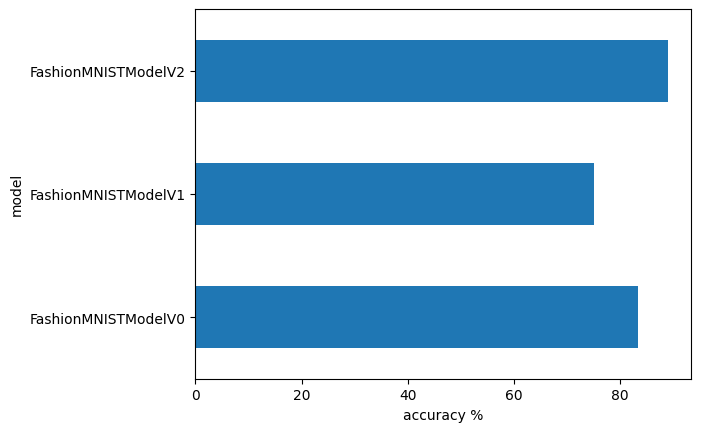

In [71]:
# visualize visualize visualize !!! the model
compare_results.set_index("model_name")["model_acc"].plot(kind="barh")
plt.xlabel("accuracy %")
plt.ylabel("model")

## 9.Make and evaluate random prediction with the best model

In [72]:
def make_predictions(model:torch.nn.Module,
                     data:list,
                     device:torch.device = device):

    pred_probs = []
    model.to(device)
    model.eval()

    with torch.no_grad():#or inference_mode
        for sample in data:
            # prepare the sample (add a batch dimension and pass to target device)
            sample = torch.unsqueeze(sample,dim=0).to(device)

            #forward pass (model outputs raw logits)

            pred_logits = model(sample)

            #Get predictions probability(logits -> prediction probability)
            pred_prob = torch.softmax(pred_logits.squeeze(),dim=0)

            #get pred prob and off the gpu for further calcualtion (matplotlib doesnot support GPU)
            pred_probs.append(pred_prob.cpu())

    # stack the predprobs to turn list into the tensor
    return torch.stack(pred_probs)

In [73]:
test_data

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [74]:
img , label = test_data[0][:10]
img.shape, label

(torch.Size([1, 28, 28]), 9)

In [77]:
import random
random.seed(42)

test_samples = []
test_labels = []

for sample,label in random.sample(list(test_data), k=9):#k=9 代表從 test_data 中隨機抽取 9 筆不重複的資料
    test_samples.append(sample)
    test_labels.append(label)

test_samples[1].shape

torch.Size([1, 28, 28])

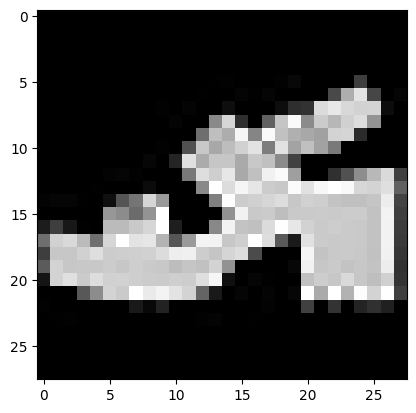

In [78]:
plt.imshow(test_samples[0].squeeze(),cmap="gray")

In [79]:
# make prediction

pred_probs = make_predictions(model=model_2,
                              data=test_samples)

#view first two prediction

pred_probs

tensor([[8.5780e-08, 3.9717e-11, 5.6225e-10, 8.4056e-10, 1.8587e-09, 1.0000e+00,
         1.1149e-07, 3.6101e-09, 5.8808e-07, 1.0743e-06],
        [2.3625e-02, 8.9662e-01, 1.2178e-04, 4.6142e-02, 3.1053e-02, 2.5126e-05,
         2.2534e-03, 1.2737e-04, 1.2157e-05, 1.5617e-05],
        [6.0864e-06, 4.3213e-08, 2.1414e-06, 1.4197e-07, 2.1318e-07, 5.9547e-04,
         7.2294e-06, 9.0429e-01, 8.7733e-05, 9.5011e-02],
        [3.9279e-05, 9.5604e-06, 5.6433e-03, 3.1868e-05, 9.9410e-01, 5.7257e-08,
         1.7614e-04, 1.5380e-07, 5.8370e-07, 1.4681e-06],
        [4.0485e-02, 2.9967e-06, 1.0519e-05, 9.5072e-01, 2.0519e-04, 3.5097e-06,
         8.5140e-03, 3.2167e-06, 4.5835e-05, 8.6685e-06],
        [6.6051e-01, 3.5394e-06, 2.3199e-04, 1.2088e-03, 2.4692e-03, 4.1331e-08,
         3.3553e-01, 3.2748e-06, 4.9813e-05, 8.6235e-08],
        [3.0459e-04, 1.2034e-06, 9.9255e-02, 7.7541e-07, 8.8156e-01, 4.7848e-07,
         1.8269e-02, 5.0976e-07, 6.0322e-04, 2.4519e-06],
        [1.1004e-06, 2.3677

In [80]:
# convert prediction probailities to labels
pred_classes = pred_probs.argmax(dim=1)# The outputs are indexes
pred_classes

tensor([5, 1, 7, 4, 3, 0, 4, 7, 1])

In [83]:
pred_classes.shape

torch.Size([9])

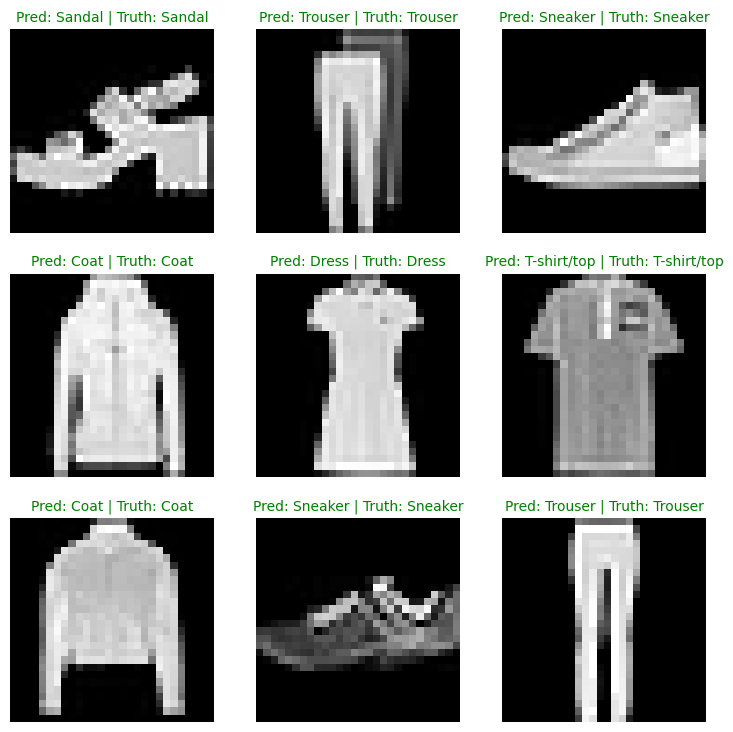

In [84]:
# Plot predictions
plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  # Create a subplot
  plt.subplot(nrows, ncols, i+1)

  # Plot the target image
  plt.imshow(sample.squeeze(), cmap="gray")

  # Find the prediction label (in text form, e.g. "Sandal")
  pred_label = class_names[pred_classes[i]]

  # Get the truth label (in text form, e.g. "T-shirt")
  truth_label = class_names[test_labels[i]]

  # Create the title text of the plot
  title_text = f"Pred: {pred_label} | Truth: {truth_label}"

  # Check for equality and change title colour accordingly
  if pred_label == truth_label:
      plt.title(title_text, fontsize=10, c="g") # green text if correct
  else:
      plt.title(title_text, fontsize=10, c="r") # red text if wrong
  plt.axis(False);

## 10.making the confusion matrix

In [86]:
from tqdm.auto import tqdm

#make prediction with trained model

y_preds=[]
model_2.eval()

with torch.no_grad():
    for X,y in tqdm(test_dataloader,desc="making_prediction...."):
      X,y = X.to(device),y.to(device)

      y_logit = model_2(X)
      y_pred = torch.softmax(y_logit,dim=1).argmax(dim=1)

      y_preds.append(y_pred.cpu())#for matplotlib

y_pred_tensor = torch.cat(y_preds)# Concatenate all prediction tensors into a single tensor.
y_pred_tensor

making_prediction....:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1,  ..., 8, 1, 5])

In [87]:
y_pred_tensor.shape

torch.Size([10000])

In [88]:
len(y_pred_tensor)

10000

In [90]:
# See if torchmetrics exists, if not, install it
try:
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")
    assert int(mlxtend.__version__.split(".")[1]) >= 19, "mlxtend verison should be 0.19.0 or higher"
except:
    !pip install -q torchmetrics -U mlxtend # <- Note: If you're using Google Colab, this may require restarting the runtime
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
mlxtend version: 0.25.0


In [92]:
# Import mlxtend upgraded version
import mlxtend
print(mlxtend.__version__)
assert int(mlxtend.__version__.split(".")[1]) >= 19 # should be version 0.19.0 or higher

0.25.0


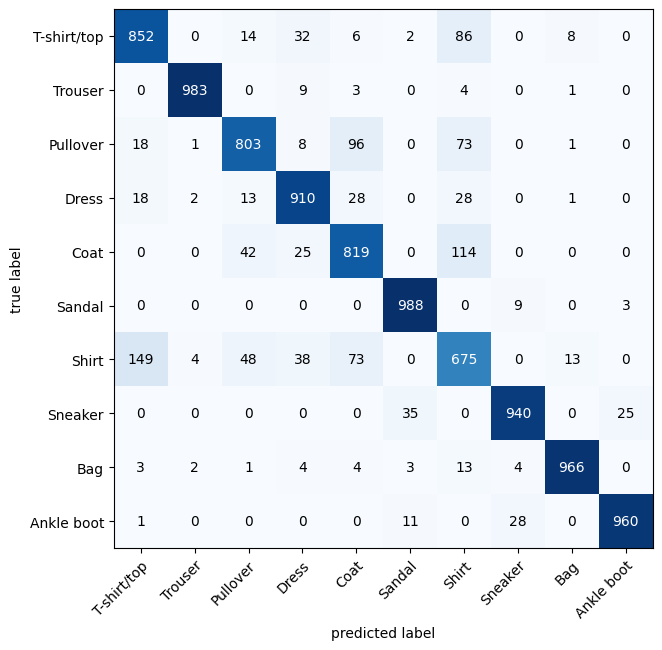

In [93]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# 建立混淆矩陣計算器
confmat = ConfusionMatrix(
    num_classes=len(class_names),
    task="multiclass"
)

# 比較模型預測與真實標籤
confmat_tensor = confmat(
    preds=y_pred_tensor,
    target=test_data.targets
)

# 3.Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),#matplotlib can't use tensor
    class_names=class_names,
    figsize=(10, 7)
)

11. Save and load best perfoming model

In [94]:
from pathlib import Path

#create model directory path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,
                 exist_ok=True)


#create model save

MODEL_NAME = "03_Pytorch_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# saving the model statedict

print(f"Saving the model: {MODEL_SAVE_PATH}")
torch.save(obj=model_2.state_dict(),
           f=MODEL_SAVE_PATH)
#torch.save(model_2.state_dict(), MODEL_SAVE_PATH)

Saving the model: models/03_Pytorch_computer_vision_model_2.pth


In [95]:
# create a new instance

torch.manual_seed(42)

loaded_model_2 = FashionMNISTModelV2(input_shape=1,
                                     hidden_units=10,
                                     output_shape=len(class_names))

# load in the save state_dict,load the learned parameters into the new model.
loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))#load_state_dict also is provided by pytorch

loaded_model_2.to(device)

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [98]:
next(loaded_model_2.parameters()).device

device(type='cuda', index=0)

In [99]:
loaded_model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.3488,  0.1533, -0.0817],
                        [ 0.3441, -0.1640,  0.1285],
                        [-0.4312,  0.3251,  0.0831]]],
              
              
                      [[[-0.4497,  0.1509,  0.3094],
                        [ 0.0594,  0.5697, -0.1297],
                        [ 0.1002,  0.3050, -0.2779]]],
              
              
                      [[[-0.0316, -0.0824,  0.1608],
                        [-0.8818, -0.9034,  0.4500],
                        [-1.0062, -0.8755, -0.2097]]],
              
              
                      [[[-0.9169, -1.1357, -0.4983],
                        [-0.1226, -1.2396, -0.0439],
                        [ 0.4643, -0.0333,  0.2988]]],
              
              
                      [[[ 0.0510,  0.4190, -0.0743],
                        [ 0.1154,  0.4497, -0.8060],
                        [ 0.3221,  0.2929, -0.4627]]],
              
              
      

In [100]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.3488,  0.1533, -0.0817],
                        [ 0.3441, -0.1640,  0.1285],
                        [-0.4312,  0.3251,  0.0831]]],
              
              
                      [[[-0.4497,  0.1509,  0.3094],
                        [ 0.0594,  0.5697, -0.1297],
                        [ 0.1002,  0.3050, -0.2779]]],
              
              
                      [[[-0.0316, -0.0824,  0.1608],
                        [-0.8818, -0.9034,  0.4500],
                        [-1.0062, -0.8755, -0.2097]]],
              
              
                      [[[-0.9169, -1.1357, -0.4983],
                        [-0.1226, -1.2396, -0.0439],
                        [ 0.4643, -0.0333,  0.2988]]],
              
              
                      [[[ 0.0510,  0.4190, -0.0743],
                        [ 0.1154,  0.4497, -0.8060],
                        [ 0.3221,  0.2929, -0.4627]]],
              
              
      

In [101]:
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.29967784881591797,
 'model_acc': 88.9576677316294}

In [108]:
torch.manual_seed(42)

loaded_model_2_results=eval_model(
    model=loaded_model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn,
    device=device
)
print(f"model_2:{model_2_results}")
print(f"loaded_model_2:{loaded_model_2_results}")


model_2:{'model_name': 'FashionMNISTModelV2', 'model_loss': 0.29967784881591797, 'model_acc': 88.9576677316294}
loaded_model_2:{'model_name': 'FashionMNISTModelV2', 'model_loss': 0.29967784881591797, 'model_acc': 88.9576677316294}


In [109]:
# check if model results are close to each other
torch.isclose(torch.tensor(model_2_results["model_loss"]),
              torch.tensor(loaded_model_2_results["model_loss"]),
              atol=1e-02)

tensor(True)